# Xử lí kiểu dữ liệu

In [78]:
import pandas as pd

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [79]:
# xóa cột customerID (cột này không có ý nghĩa trong huấn luyện)
df = df.drop(columns=['customerID'])
print(df.shape[1])

20


In [80]:
# ép cột TotalCharges về dạng số thực, nếu có những giá trị trống thì để về NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df['TotalCharges'].isnull().sum())

11


In [81]:
# Thấy 11 dòng bị khuyết này đều không sử dụng dịch vụ tháng nào
print(df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']])

      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


In [82]:
# fillna: dùng để thay thế các giá trị rỗng
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [83]:
print(df['TotalCharges'].dtype)

float64


# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

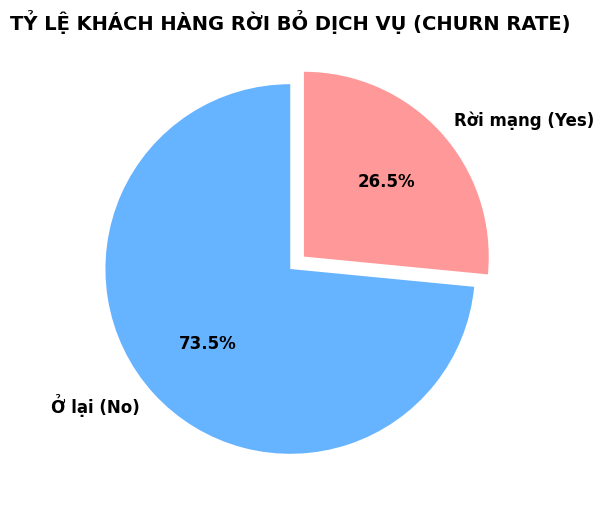

Tổng số khách ở lại: 5174 (73.5%)
Tổng số khách rời mạng: 1869 (26.5%)
Tập dữ liệu gặp hiện tượng mất cân bằng lớp (Class Imbalance) rõ rệt: có tới 73.5% khách hàng ở lại và chỉ có 26.5% khách hàng rời mạng (tỷ lệ gần 3:1). Do đó, việc chỉ dùng Accuracy để đánh giá mô hình sẽ bị sai lệch, cần phải kết hợp Precision, Recall, F1-Score và AUC-ROC.


In [98]:
import pandas as pd
import matplotlib.pyplot as plt

# Đọc bản sao dữ liệu để phân tích khám phá (EDA)
df_eda = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df_eda['TotalCharges'] = pd.to_numeric(df_eda['TotalCharges'], errors='coerce').fillna(0)

# Vẽ biểu đồ tròn thể hiện tỷ lệ Churn
churn_counts = df_eda['Churn'].value_counts()
colors = ['#66b3ff', '#ff9999']

plt.figure(figsize=(6, 6))
plt.pie(churn_counts, 
        labels=['Ở lại (No)', 'Rời mạng (Yes)'], 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=colors, 
        explode=(0, 0.1),
        textprops={'fontsize': 12, 'fontweight': 'bold'})

plt.title('TỶ LỆ KHÁCH HÀNG RỜI BỎ DỊCH VỤ (CHURN RATE)', fontsize=14, fontweight='bold')
plt.show()

print(f"Tổng số khách ở lại: {churn_counts['No']} ({churn_counts['No']/len(df_eda):.1%})")
print(f"Tổng số khách rời mạng: {churn_counts['Yes']} ({churn_counts['Yes']/len(df_eda):.1%})")
print("Tập dữ liệu gặp hiện tượng mất cân bằng lớp (Class Imbalance) rõ rệt: có tới 73.5% khách hàng ở lại và chỉ có 26.5% khách hàng rời mạng (tỷ lệ gần 3:1). Do đó, việc chỉ dùng Accuracy để đánh giá mô hình sẽ bị sai lệch, cần phải kết hợp Precision, Recall, F1-Score và AUC-ROC.")

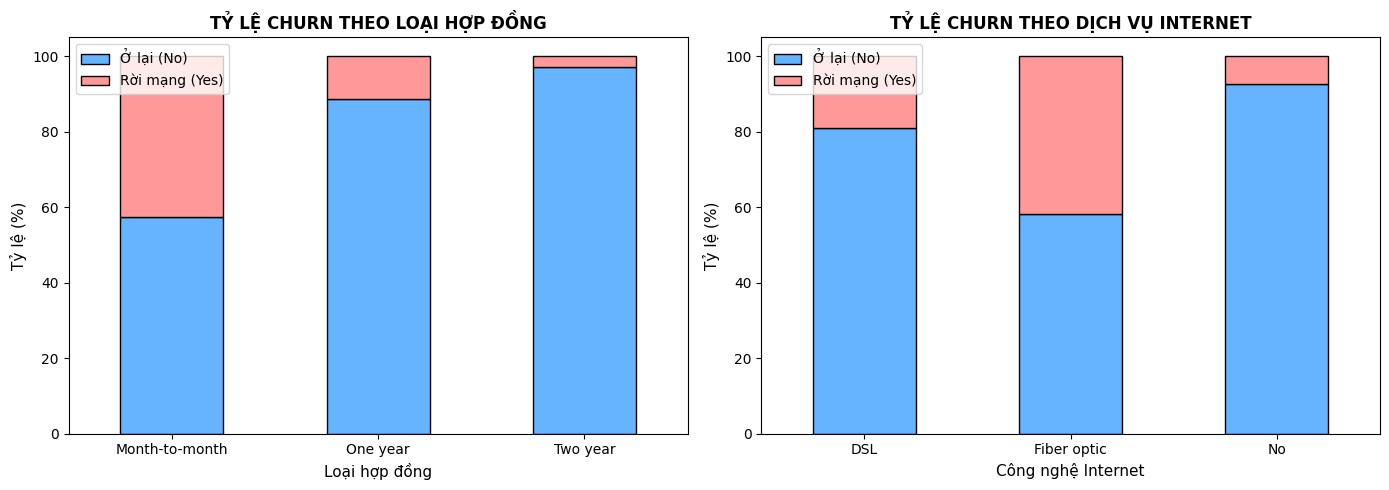

Về hợp đồng: Khách hàng dùng hợp đồng theo tháng (Month-to-month) có tỷ lệ rời mạng lên tới 42.7%, trong khi khách ký 2 năm chỉ rời mạng 2.8% (chênh lệch gấp hơn 15 lần). Loại hợp đồng là một Key Churn Driver hàng đầu.
Về Internet: Khách dùng cáp quang (Fiber optic) có tỷ lệ rời mạng lên tới 41.9%, cao hơn nhiều so với cáp đồng DSL (18.9%) do giá thành cáp quang cao hơn và khách hàng có yêu cầu khắt khe hơn về chất lượng mạng.


In [100]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Tỷ lệ Churn theo loại hợp đồng (Contract)
contract_churn = pd.crosstab(df_eda['Contract'], df_eda['Churn'], normalize='index') * 100
contract_churn.plot(kind='bar', stacked=True, color=['#66b3ff', '#ff9999'], ax=axes[0], edgecolor='black')
axes[0].set_title('TỶ LỆ CHURN THEO LOẠI HỢP ĐỒNG', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Tỷ lệ (%)', fontsize=11)
axes[0].set_xlabel('Loại hợp đồng', fontsize=11)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(['Ở lại (No)', 'Rời mạng (Yes)'])

# 2. Tỷ lệ Churn theo công nghệ Internet (InternetService)
internet_churn = pd.crosstab(df_eda['InternetService'], df_eda['Churn'], normalize='index') * 100
internet_churn.plot(kind='bar', stacked=True, color=['#66b3ff', '#ff9999'], ax=axes[1], edgecolor='black')
axes[1].set_title('TỶ LỆ CHURN THEO DỊCH VỤ INTERNET', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Tỷ lệ (%)', fontsize=11)
axes[1].set_xlabel('Công nghệ Internet', fontsize=11)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(['Ở lại (No)', 'Rời mạng (Yes)'])

plt.tight_layout()
plt.show()
print("Về hợp đồng: Khách hàng dùng hợp đồng theo tháng (Month-to-month) có tỷ lệ rời mạng lên tới 42.7%, trong khi khách ký 2 năm chỉ rời mạng 2.8% (chênh lệch gấp hơn 15 lần). Loại hợp đồng là một Key Churn Driver hàng đầu.")
print("Về Internet: Khách dùng cáp quang (Fiber optic) có tỷ lệ rời mạng lên tới 41.9%, cao hơn nhiều so với cáp đồng DSL (18.9%) do giá thành cáp quang cao hơn và khách hàng có yêu cầu khắt khe hơn về chất lượng mạng.")

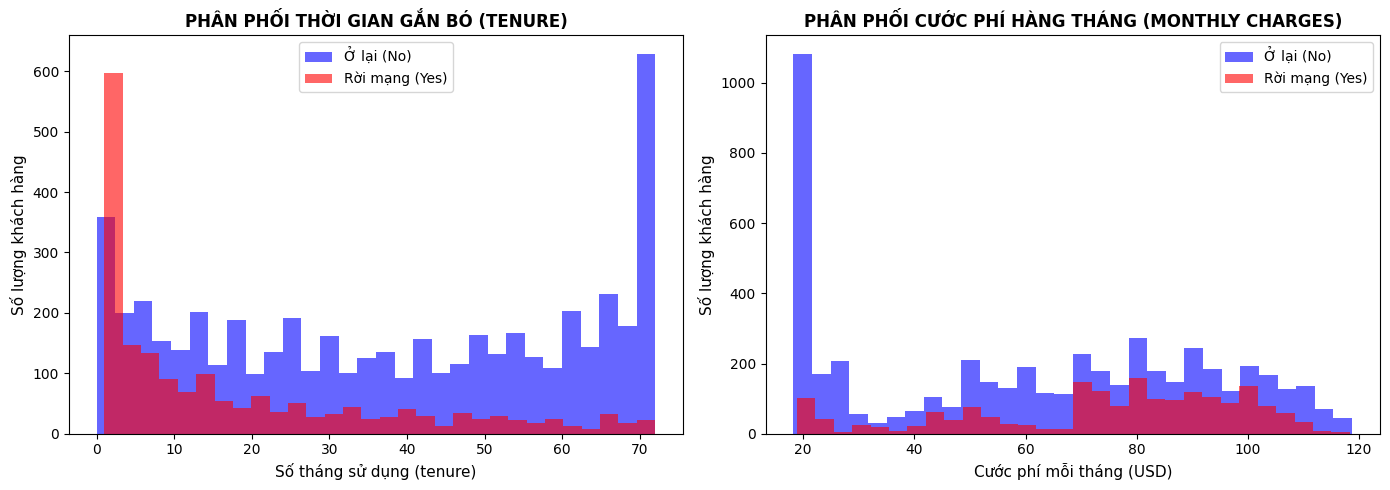

=== THỐNG KÊ TRUNG BÌNH GIỮA 2 NHÓM KHÁCH HÀNG ===
       tenure  MonthlyCharges
Churn                        
No      37.57           61.27
Yes     17.98           74.44
Thời gian gắn bó: Khách rời mạng tập trung áp đảo ở những tháng đầu tiên (trung bình thời gian dùng của nhóm rời mạng chỉ là 18 tháng, trong khi nhóm ở lại là 37.6 tháng). Càng dùng lâu, khách càng trung thành.
Cước phí: Nhóm khách rời mạng phải gánh mức cước trung bình cao hơn hẳn. Mức phí đắt đỏ là lý do trực tiếp khiến khách hàng tìm kiếm nhà mạng khác


In [101]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Phân phối thời gian gắn bó (tenure) giữa 2 nhóm
df_eda[df_eda['Churn'] == 'No']['tenure'].plot(kind='hist', bins=30, alpha=0.6, color='blue', ax=axes[0], label='Ở lại (No)')
df_eda[df_eda['Churn'] == 'Yes']['tenure'].plot(kind='hist', bins=30, alpha=0.6, color='red', ax=axes[0], label='Rời mạng (Yes)')
axes[0].set_title('PHÂN PHỐI THỜI GIAN GẮN BÓ (TENURE)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Số tháng sử dụng (tenure)', fontsize=11)
axes[0].set_ylabel('Số lượng khách hàng', fontsize=11)
axes[0].legend()

# 2. Phân phối mức cước hàng tháng (MonthlyCharges) giữa 2 nhóm
df_eda[df_eda['Churn'] == 'No']['MonthlyCharges'].plot(kind='hist', bins=30, alpha=0.6, color='blue', ax=axes[1], label='Ở lại (No)')
df_eda[df_eda['Churn'] == 'Yes']['MonthlyCharges'].plot(kind='hist', bins=30, alpha=0.6, color='red', ax=axes[1], label='Rời mạng (Yes)')
axes[1].set_title('PHÂN PHỐI CƯỚC PHÍ HÀNG THÁNG (MONTHLY CHARGES)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cước phí mỗi tháng (USD)', fontsize=11)
axes[1].set_ylabel('Số lượng khách hàng', fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.show()

# In thống kê trung bình
print("=== THỐNG KÊ TRUNG BÌNH GIỮA 2 NHÓM KHÁCH HÀNG ===")
print(df_eda.groupby('Churn')[['tenure', 'MonthlyCharges']].mean().round(2))
print("Thời gian gắn bó: Khách rời mạng tập trung áp đảo ở những tháng đầu tiên (trung bình thời gian dùng của nhóm rời mạng chỉ là 18 tháng, trong khi nhóm ở lại là 37.6 tháng). Càng dùng lâu, khách càng trung thành.")
print("Cước phí: Nhóm khách rời mạng phải gánh mức cước trung bình cao hơn hẳn. Mức phí đắt đỏ là lý do trực tiếp khiến khách hàng tìm kiếm nhà mạng khác")

# Mã hóa biến phân loại

In [84]:
# Các nhãn như "No internet service" hay "No phone service" thì đều sẽ chuyển về "No"

replace_cols = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

for cols in replace_cols:
    df[cols] = df[cols].replace({'No internet service': 'No', 'No phone service': 'No'}) 

In [85]:
# Đổi các cột nhị phân Yes/No, Male/Female thành 0,1
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines',
               'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
               'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'Churn']

for col in binary_cols:
    df[col] = df[col].replace({'Yes': 1, 'No': 0}).astype(int)  

df['gender'] = df['gender'].replace({'Male': 1, 'Female': 0}).astype(int)  

In [86]:
# Mã hóa One-hot (Do có nhiều giá trị trong 1 bảng, nên phải sử dụng loại mã hóa này)

df = pd.get_dummies(df, columns=['InternetService', 'Contract', 'PaymentMethod'], drop_first=True, dtype=int)
print(df.shape)
print(df.dtypes)

(7043, 24)
gender                                     int64
SeniorCitizen                              int64
Partner                                    int64
Dependents                                 int64
tenure                                     int64
PhoneService                               int64
MultipleLines                              int64
OnlineSecurity                             int64
OnlineBackup                               int64
DeviceProtection                           int64
TechSupport                                int64
StreamingTV                                int64
StreamingMovies                            int64
PaperlessBilling                           int64
MonthlyCharges                           float64
TotalCharges                             float64
Churn                                      int64
InternetService_Fiber optic                int64
InternetService_No                         int64
Contract_One year                          int64
Contract_

# Tách dữ liệu, Chia tập Train/Test và Chuẩn hóa

In [87]:
# tách biến độc lập x và biến mục tiêu y
x = df.drop(columns=['Churn'])
y = df['Churn']
print(x.shape)
print(y.shape)

(7043, 23)
(7043,)


In [88]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
) 

print(f"Số lượng mẫu tập Train: {x_train.shape[0]} ({x_train.shape[0]/len(df):.0%})")
print(f"Số lượng mẫu tập Test:  {x_test.shape[0]} ({x_test.shape[0]/len(df):.0%})")

Số lượng mẫu tập Train: 5634 (80%)
Số lượng mẫu tập Test:  1409 (20%)


In [89]:
from sklearn.preprocessing import StandardScaler

#Danh sách 3 cột cần chuẩn hóa vì các giá trị cách quá xa nhau
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()

#Chuẩn hóa trên tập x_train và x_test
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

x_train[num_cols].head()

,tenure,MonthlyCharges,TotalCharges
3738,0.102371,-0.521976,-0.262257
3151,-0.711743,0.337478,-0.503635
4860,-0.793155,-0.809013,-0.749883
3867,-0.263980,0.284384,-0.172722
3810,-1.281624,-0.676279,-0.989374


# Khởi tạo và cho 3 thuật toán cùng học trên tập Train

In [90]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Khởi tạo 3 mô hình huấn luyện
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_model = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')

# Cho 3 mô hình bắt đầu học
dt_model.fit(x_train, y_train)
rf_model.fit(x_train, y_train)
xgb_model.fit(x_train, y_train)

print("Done")

Done


In [91]:
from  sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

models = {
    'Decision Tree': dt_model,
    'Random Tree': rf_model,
    'XGBoost': xgb_model
}

results = []

for name, model in models.items():
    # Dự đoán tập test là 0 hay 1
    y_pred = model.predict(x_test)

    # Dự đoán xác suất rơi vào lớp 1 (Churn = Yes) để tính AUC-ROC
    y_prob = model.predict_proba(x_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'AUC-ROC': round(roc_auc_score(y_test, y_prob), 4)
    })

result_df = pd.DataFrame(results)
display(result_df)

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Decision Tree,0.7942,0.6312,0.5401,0.5821,0.8267
1,Random Tree,0.7899,0.6327,0.4973,0.5569,0.8290
2,XGBoost,0.7722,0.5831,0.4973,0.5368,0.8224


# Biểu Đồ 1: So Sánh Trực Quan 5 Chỉ Số Giữa 3 Mô Hình

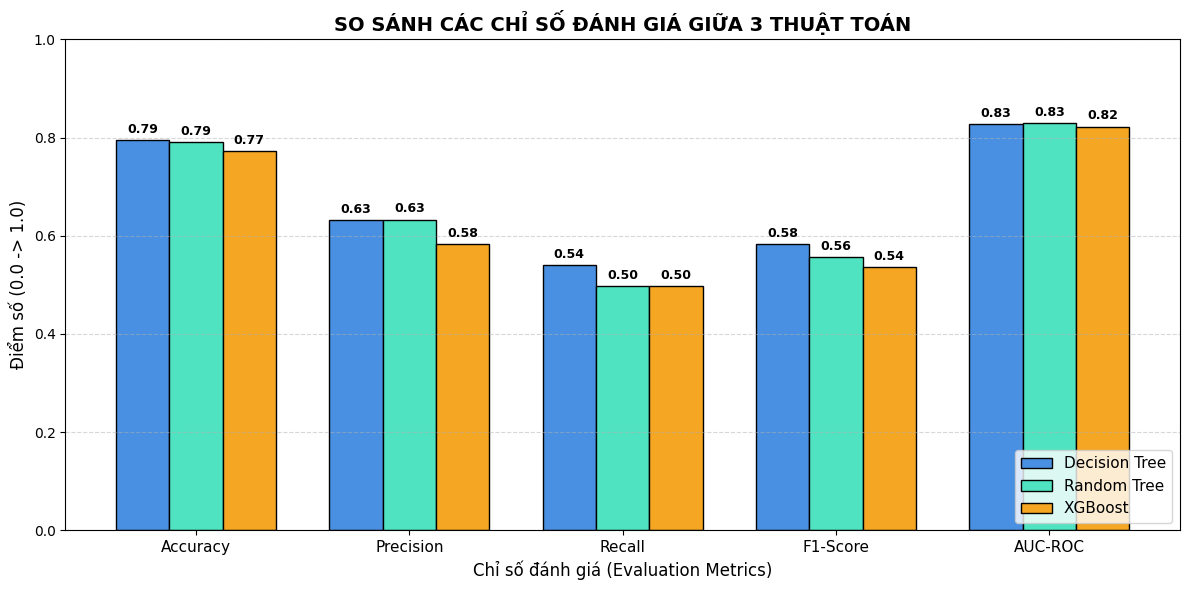

In [92]:
import matplotlib.pyplot as plt
import numpy as np

# Chuẩn bị dữ liệu từ result_df
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
models_name = result_df['Model'].tolist()

x = np.arange(len(metrics))  
width = 0.25                

plt.figure(figsize=(12, 6))

colors = ['#4A90E2', '#50E3C2', '#F5A623']
for i, name in enumerate(models_name):
    values = result_df.loc[result_df['Model'] == name, metrics].values[0]
    rects = plt.bar(x + i * width, values, width, label=name, color=colors[i], edgecolor='black')
    
    # Hiển thị số điểm cụ thể trên đầu mỗi cột
    for rect in rects:
        height = rect.get_height()
        plt.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('SO SÁNH CÁC CHỈ SỐ ĐÁNH GIÁ GIỮA 3 THUẬT TOÁN', fontsize=14, fontweight='bold')
plt.xlabel('Chỉ số đánh giá (Evaluation Metrics)', fontsize=12)
plt.ylabel('Điểm số (0.0 -> 1.0)', fontsize=12)
plt.xticks(x + width, metrics, fontsize=11)
plt.ylim(0, 1.0)
plt.legend(loc='lower right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Biểu Đồ 2: Đường Cong ROC (ROC Curve) Của Cả 3 Mô Hình

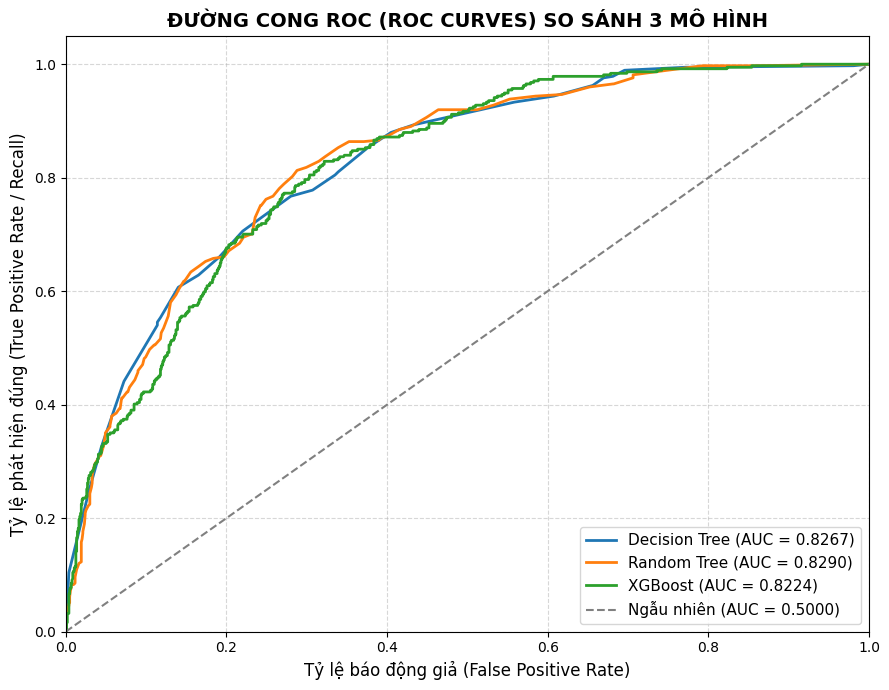

In [93]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))

# Vẽ đường cong ROC cho từng mô hình
for name, model in models.items():
    y_prob = model.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.4f})')

# Vẽ đường ngẫu nhiên chuẩn 45 độ (mô hình đoán mò)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Ngẫu nhiên (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỷ lệ báo động giả (False Positive Rate)', fontsize=12)
plt.ylabel('Tỷ lệ phát hiện đúng (True Positive Rate / Recall)', fontsize=12)
plt.title('ĐƯỜNG CONG ROC (ROC CURVES) SO SÁNH 3 MÔ HÌNH', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Biểu Đồ 3: Ma Trận Nhầm Lẫn (Confusion Matrix) Của Mô Hình Chiến Thắng

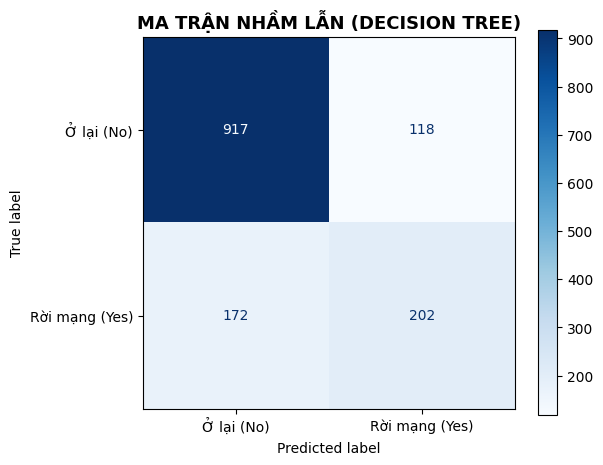

- Đoán đúng khách ở lại (TN): 917 người
- Đoán đúng khách rời mạng (TP): 202 người
- Báo động nhầm (FP): 118 người (khách ở lại nhưng máy tưởng bỏ đi)
- Bỏ sót khách rời mạng (FN): 172 người (khách bỏ đi mà máy không biết)


In [94]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Dự đoán từ mô hình Decision Tree
y_pred_dt = dt_model.predict(x_test)
cm = confusion_matrix(y_test, y_pred_dt)

# Vẽ ma trận nhầm lẫn
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ở lại (No)', 'Rời mạng (Yes)'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')

plt.title('MA TRẬN NHẦM LẪN (DECISION TREE)', fontsize=13, fontweight='bold')
plt.show()

# In diễn giải bằng lời
tn, fp, fn, tp = cm.ravel()
print(f"- Đoán đúng khách ở lại (TN): {tn} người")
print(f"- Đoán đúng khách rời mạng (TP): {tp} người")
print(f"- Báo động nhầm (FP): {fp} người (khách ở lại nhưng máy tưởng bỏ đi)")
print(f"- Bỏ sót khách rời mạng (FN): {fn} người (khách bỏ đi mà máy không biết)")